# Metric Design, Funnels, and Growth Accounting

**What you'll learn**

- How to design a metric system, not just a metric: a north-star metric plus an
  input-metric tree (built concretely for a two-sided marketplace), the output-vs-input and
  leading-vs-lagging distinctions, and where guardrails and counter-metrics fit.
- What "good metric" actually means operationally — sensitive, robust, directionally
  interpretable, hard to game — and how to *quantify* sensitivity as the sample size an
  experiment needs to move it.
- Goodhart's law with real failure stories (clickbait CTR, ticket-closure speed, sales
  quotas) and the counter-metric pattern that fixes them, demonstrated in simulation.
- Funnel analysis in pandas: step conversion, segment cuts, and a headroom analysis that
  finds the *binding constraint* — the step×segment where effort buys the most purchases.
- The classic senior interview task: decompose a period-over-period conversion change into
  **mix shift** vs **within-segment rate change**, implemented two ways and verified to
  sum exactly.
- Cohort retention matrices and curve families, then growth accounting: the
  new/retained/resurrected/churned identity, the quick ratio, and the growth waterfall.

**Why it matters in interviews**

- "Define a success metric for feature X" and "what makes a metric good vs bad" open most
  product-analytics interviews; the strong answer is a framework plus counter-metrics, not
  a single number.
- "DAU dropped 8% — investigate" is the canonical metric-investigation case. Growth
  accounting and mix/rate decomposition *are* the investigation tools.
- "Conversion fell but every segment improved — explain" tests whether you can implement
  a decomposition on the spot, not just name Simpson's paradox.
- Marketplace and growth-team interviews expect fluency with retention curves, quick
  ratio, and what the shapes imply about product-market fit.

Everything runs on simulated data with **planted ground truth** (a broken Android cart
step, a channel-mix shift, an improving retention plateau), so each method can be checked
against what we know is really there. The SQL versions of funnels and retention live in
[../07_sql_and_big_data/02_sql_product_analytics.ipynb](../07_sql_and_big_data/02_sql_product_analytics.ipynb);
churn and LTV modeling continue in
[./02_churn_survival.ipynb](./02_churn_survival.ipynb) and
[./03_ltv_modeling.ipynb](./03_ltv_modeling.ipynb).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy import stats
from scipy.optimize import curve_fit

rng = np.random.default_rng(42)

plt.rcParams.update({
    "figure.figsize": (8.0, 4.2),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.autolayout": True,
})
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 4)

pct0 = mticker.PercentFormatter(xmax=1, decimals=0)

## 1. Metric design: north star + input tree

A single KPI is not a metric system. Mature product organizations run on a **north-star
metric** (one number that proxies long-run value creation) plus an **input-metric tree**
(the levers teams can actually move) plus **guardrails** (things you must not break while
moving them). The design distinctions that come up in interviews:

| Distinction | Definition | Example |
|---|---|---|
| **Output metric** | Result of many systems; nobody can move it directly | weekly completed purchases, revenue |
| **Input metric** | Owned by one team; causally upstream of an output | search→product-page CTR, on-time ship rate |
| **Lagging indicator** | Confirms value after the fact; slow feedback | LTV, annual retention, revenue |
| **Leading indicator** | Moves early and predicts the lagging one | activation rate, week-4 repeat rate |
| **Guardrail** | Org-wide "do not break" constraint | p95 latency, refund rate, unsubscribe rate |
| **Counter-metric** | Paired to a *specific* target to catch gaming it | CTR paired with post-click regret/dwell |

Good goals live at the *input* level ("raise on-time ship rate from 88% → 93%") because
inputs are sensitive, attributable, and fast. The north star is how you check the tree's
causal edges still hold — more on that failure mode in the interview corner ("north star
grew but revenue didn't").

### A concrete tree for a two-sided goods marketplace

Pick the north star first. For a marketplace where buyers purchase physical goods from
independent sellers, strong candidates and why most lose:

- **GMV / week** — value-*captured* proxy, but gamable by pushing expensive items and
  dominated by whale variance (we quantify this in section 2). Fine as a finance metric,
  weak as a north star.
- **Registered users, app downloads** — pure vanity: monotone increasing, insensitive to
  product quality.
- **DAU** — engagement is not value here; buyers of ceramics don't need to visit daily.
  For a social product DAU-like metrics are reasonable; metric choice is product-specific.
- **Weekly completed purchases (WCP)** — a purchase that is delivered and not refunded is
  the moment both sides received value. Countable, weekly-fresh, and it only grows if
  demand, supply, and matching all work. **This is the north star.**

The input tree, annotated with the team that owns each branch:

```text
Weekly Completed Purchases  (north star — output, lagging)
├── DEMAND (growth team)
│   ├── Active buyers = new + retained + resurrected      ← growth accounting, §7
│   │   ├── New-buyer activation: first purchase ≤ 14d of signup   (leading)
│   │   └── Buyer 12-week repeat-purchase rate                     (leading, LTV proxy)
│   └── Orders per active buyer
│       ├── Visit → purchase conversion                    ← funnel, §4
│       └── Purchase frequency / buyer
├── SUPPLY (seller team)
│   ├── Active sellers with ≥ 1 in-stock listing
│   ├── Listing coverage: % searches with ≥ 5 relevant results     (leading)
│   └── On-time ship rate                                  (quality input)
└── MATCHING (search/discovery team)
    ├── Search → product-page CTR
    └── Product page → add-to-cart rate

Guardrails: refund + dispute rate, support contacts per 1k orders,
            take-rate revenue per order, seller 4-week churn, p95 search latency
```

Two properties make this a *tree* and not a dashboard. First, every edge is a claimed
causal link ("more listing coverage → more conversion") that can and should be validated
with experiments (see [../02_ab_testing/01_ab_test_end_to_end.ipynb](../02_ab_testing/01_ab_test_end_to_end.ipynb)).
Second, every team goal is an input paired with a guardrail from another branch — the
seller team can't hit "more listings" by tolerating junk inventory because listing
coverage is paired with refund rate.

## 2. What makes a metric good

The standard criteria, stated operationally:

- **Sensitive** — realistic product changes move it detectably at your traffic level.
  Quantifiable: sensitivity is governed by the metric's coefficient of variation (CV),
  which sets experiment sample size.
- **Robust** — not dominated by outliers, bots, or a handful of whales; stable
  definition; doesn't jump when a logging library updates.
- **Directionally interpretable** — everyone agrees which way is good. "Support tickets
  down" is ambiguous (fewer problems, or users gave up?); "refund rate down" is not.
- **Hard to game** — moving the metric without creating value should be difficult, or at
  least detectable via a paired counter-metric (§3).

Scoring marketplace candidates against these (the kind of table worth sketching in an
interview):

| Candidate metric | Sensitive | Robust | Directional | Hard to game | Verdict |
|---|---|---|---|---|---|
| Weekly completed purchases | Med (count metric) | High | High | High (requires real delivery) | **North star** |
| GMV / week | Low (whale variance) | Low | Med (price-mix moves it) | Med (push expensive items) | Finance reporting |
| Buyer 4-wk repeat rate | Low-Med (slow) | High | High | High | Team input (leading) |
| Search CTR | High | High | **Low** (clickbait raises it) | **Low** | Input, needs counter-metric |
| Sessions / user | High | Med | Low (frustration adds sessions) | Low | Diagnostic only |
| Revenue / session | Low | Low | Med | Med | Avoid as target |
| NPS | Low (survey n) | Low (response bias) | Med | Low (prompt timing) | Directional check only |

The "Sensitive" column is not hand-waving — it converts directly into how long an A/B
test must run. Below we simulate one user population and compute, for each candidate
metric, the per-arm sample size needed to detect a +2% relative lift (α=5%, power 80%);
formula from [../02_ab_testing/02_power_mde_sample_size.ipynb](../02_ab_testing/02_power_mde_sample_size.ipynb).

In [2]:
n_users = 200_000
converted = rng.random(n_users) < 0.06                       # 6% visit→purchase
spend = np.where(converted, rng.lognormal(3.6, 1.1, n_users), 0.0)   # heavy-tailed basket
sessions = rng.poisson(3.2, n_users) + 1                     # sessions in the window

cap99 = np.quantile(spend, 0.99)
spend_capped = np.minimum(spend, cap99)


def n_per_arm(x, rel_mde=0.02, alpha=0.05, power=0.80):
    """Per-arm n to detect a relative lift of rel_mde on metric x (two-sided z-test)."""
    z = stats.norm.ppf(1 - alpha / 2) + stats.norm.ppf(power)
    cv = x.std() / x.mean()
    return 2 * (z * cv / rel_mde) ** 2


candidates = {
    "conversion (binary)": converted.astype(float),
    "revenue per user": spend,
    f"revenue capped at p99 (${cap99:.0f})": spend_capped,
    "sessions per user": sessions.astype(float),
}
sens = pd.DataFrame(
    {
        "mean": {k: v.mean() for k, v in candidates.items()},
        "CV": {k: v.std() / v.mean() for k, v in candidates.items()},
        "n_per_arm_for_+2%": {k: n_per_arm(v) for k, v in candidates.items()},
    }
)
sens["weeks_at_150k/arm/wk"] = sens["n_per_arm_for_+2%"] / 150_000
print(sens.round({"mean": 3, "CV": 2, "n_per_arm_for_+2%": 0, "weeks_at_150k/arm/wk": 1}))
print(f"\nrevenue vs conversion sample-size penalty: "
      f"{sens.loc['revenue per user', 'n_per_arm_for_+2%'] / sens.loc['conversion (binary)', 'n_per_arm_for_+2%']:.1f}x")

                               mean    CV  n_per_arm_for_+2%  weeks_at_150k/arm/wk
conversion (binary)           0.060  3.98           620104.0                   4.1
revenue per user              4.078  8.20          2636968.0                  17.6
revenue capped at p99 ($106)  2.837  5.00           981058.0                   6.5
sessions per user             4.203  0.43             7117.0                   0.0

revenue vs conversion sample-size penalty: 4.3x


Reading the table like a senior candidate:

- **Revenue per user needs over 4x the sample of conversion** for the same relative MDE —
  entirely a CV story (heavy-tailed basket sizes on top of a binary conversion). This is
  why experiment platforms default to conversion-style primary metrics and treat revenue
  as secondary.
- **Capping at p99 buys back a lot of sensitivity**, but you are now measuring a
  *different* estimand — a change concentrated in whales becomes invisible. Winsorization
  is a variance-vs-fidelity trade, not a free lunch (see
  [../02_ab_testing/03_variance_reduction_cuped.ipynb](../02_ab_testing/03_variance_reduction_cuped.ipynb)
  for reductions that don't change the estimand).
- **Sessions per user is the sensitivity trap**: tiny CV, would "detect" effects in
  hours — but it fails the directional criterion (bugs and frustration also add
  sessions). A metric can be maximally sensitive and still be a bad target. Which brings
  us to Goodhart.

## 3. Goodhart in practice

> "When a measure becomes a target, it ceases to be a good measure."

The mechanism is always the same: the metric is a *proxy* for value; optimization
pressure finds the gap between proxy and value and pours through it. Three short
cautionary tales, each with the standard fix:

1. **Clickbait CTR.** A feed team is goaled on click-through rate. Ranking learns that
   outrage headlines and thumbnail bait get clicks. CTR climbs for two quarters while
   30-day retention quietly falls — users click more and trust less.
   *Fix:* pair CTR with a **post-click quality counter-metric** (dwell time, "quick-back"
   regret rate) and hold a long-term retention holdout group.
2. **Ticket-closure speed.** Support is goaled on mean time-to-close. Agents close
   tickets with canned non-answers; customers reopen or churn. Time-to-close improves,
   resolution collapses.
   *Fix:* measure **resolution, not closure** — pair with reopen rate within 7 days and
   post-resolution CSAT, sampled and audited.
3. **Accounts opened (Wells Fargo, 2016).** Branch staff goaled on new accounts per
   customer opened ~2M unauthorized accounts. The metric counted openings, not usage.
   *Fix:* count only **activity-qualified** units (account funded and used within 90
   days) and watch complaint rate as a guardrail.

The general pattern for the fix: (a) move the target closer to value (completed, not
clicked; resolved, not closed; funded, not opened), (b) pair every rate target with a
counter-metric on the dimension the rate ignores, (c) audit a sample by hand.

Let's simulate tale #1 to see why a CTR-only readout ships the wrong ranker.

In [3]:
n_per_policy = 30_000

# Ground truth: clickbait raises CTR 5.0% -> 8.2%, but clickbait clickers feel baited
# (7-day return 38% vs 55%) and a bait-heavy feed degrades even non-clickers (27% vs 30%).
policies = {
    "baseline":  {"ctr": 0.050, "ret_click": 0.55, "ret_noclick": 0.30},
    "clickbait": {"ctr": 0.082, "ret_click": 0.38, "ret_noclick": 0.27},
}

rows = []
for name, p in policies.items():
    clicked = rng.random(n_per_policy) < p["ctr"]
    p_ret = np.where(clicked, p["ret_click"], p["ret_noclick"])
    returned = rng.random(n_per_policy) < p_ret
    for metric, x in [("CTR", clicked), ("7-day return", returned)]:
        m = x.mean()
        se = np.sqrt(m * (1 - m) / n_per_policy)
        rows.append({"policy": name, "metric": metric, "rate": m,
                     "ci_lo": m - 1.96 * se, "ci_hi": m + 1.96 * se})

goodhart = pd.DataFrame(rows).pivot(index="metric", columns="policy",
                                    values=["rate", "ci_lo", "ci_hi"])
print((goodhart["rate"] * 100).round(2).to_string(), "\n")
d_ctr = goodhart.loc["CTR", ("rate", "clickbait")] - goodhart.loc["CTR", ("rate", "baseline")]
d_ret = (goodhart.loc["7-day return", ("rate", "clickbait")]
         - goodhart.loc["7-day return", ("rate", "baseline")])
print(f"CTR:          {d_ctr * 100:+.1f}pp  <- target metric says SHIP")
print(f"7-day return: {d_ret * 100:+.1f}pp  <- counter-metric says DO NOT SHIP")

policy        baseline  clickbait
metric                           
7-day return     31.73      27.44
CTR               4.88       8.14 

CTR:          +3.3pp  <- target metric says SHIP
7-day return: -4.3pp  <- counter-metric says DO NOT SHIP


A CTR-only scorecard ships the clickbait ranker on a +3.3pp (~+65% relative) "win"; the
paired counter-metric shows it costs about 4pp of 7-day return — users we paid to
acquire, quietly leaving. The decision rule that survives Goodhart is never "maximize
M"; it is "maximize M subject to counter-metrics flat", which is exactly how guardrail
metrics enter the experiment scorecard in
[../02_ab_testing/01_ab_test_end_to_end.ipynb](../02_ab_testing/01_ab_test_end_to_end.ipynb).

## 4. Funnel analysis: signup → purchase

Now the hands-on core. We simulate visitor-level funnel data for our marketplace over
two months, with **planted ground truth** so we can verify the analysis finds it:

- Steps per visitor: `visited → signed_up → activated → added_to_cart → purchased`
  (each conditional on the previous).
- Segments: acquisition channel (organic, paid_search, paid_social, referral) and
  platform (ios, android, web).
- **Planted defect:** the Android add-to-cart step runs at a 0.62 multiplier — a broken
  cart UX. This is the binding constraint the analysis should surface.
- **Planted dynamics for §5:** from March to April the paid-social share of traffic
  jumps (0.15 → 0.35, a big campaign) while *every* channel's own conversion improves
  (checkout redesign, multiplier 1.06 on the purchase step; small cart tweak 1.02;
  paid-social landing-page fix 1.10 on its signup step).

Real event logs give you timestamps, not booleans — strictly-ordered funnels and
sessionization are done with window functions in
[../07_sql_and_big_data/02_sql_product_analytics.ipynb](../07_sql_and_big_data/02_sql_product_analytics.ipynb);
here flags keep the analytics logic front and center.

In [4]:
CHANNELS = ["organic", "paid_search", "paid_social", "referral"]
PLATFORMS = ["ios", "android", "web"]
PLATFORM_P = [0.35, 0.40, 0.25]
STEPS = ["visited", "signed_up", "activated", "added_to_cart", "purchased"]

MIX = {"March": [0.40, 0.25, 0.15, 0.20],       # channel shares of traffic
       "April": [0.30, 0.22, 0.35, 0.13]}       # paid_social campaign scales up
N_VISITORS = {"March": 90_000, "April": 95_000}

SIGNUP_CH = {"organic": 1.15, "paid_search": 1.00, "paid_social": 0.55, "referral": 1.25}
ACT_PF = {"ios": 1.05, "android": 0.95, "web": 1.00}
ACT_CH = {"organic": 1.00, "paid_search": 1.00, "paid_social": 0.85, "referral": 1.00}
CART_PF = {"ios": 1.15, "android": 0.62, "web": 1.00}     # <- planted Android cart bug
PURCH_CH = {"organic": 1.00, "paid_search": 1.00, "paid_social": 0.80, "referral": 1.00}
PURCH_PF = {"ios": 1.00, "android": 0.95, "web": 1.00}

APRIL_CART_MULT = 1.02        # small cart tweak shipped Apr 1
APRIL_PURCH_MULT = 1.06       # checkout redesign shipped Apr 1
APRIL_PS_SIGNUP_MULT = 1.10   # paid-social landing-page fix


def simulate_period(period: str, n: int) -> pd.DataFrame:
    df = pd.DataFrame({
        "period": period,
        "channel": rng.choice(CHANNELS, size=n, p=MIX[period]),
        "platform": rng.choice(PLATFORMS, size=n, p=PLATFORM_P),
    })
    april = period == "April"
    p_signup = 0.32 * df["channel"].map(SIGNUP_CH)
    if april:
        p_signup *= np.where(df["channel"] == "paid_social", APRIL_PS_SIGNUP_MULT, 1.0)
    p_act = 0.68 * df["platform"].map(ACT_PF) * df["channel"].map(ACT_CH)
    p_cart = 0.46 * df["platform"].map(CART_PF) * (APRIL_CART_MULT if april else 1.0)
    p_purch = (0.58 * df["channel"].map(PURCH_CH) * df["platform"].map(PURCH_PF)
               * (APRIL_PURCH_MULT if april else 1.0))

    u = rng.random((n, 4))
    df["visited"] = True
    df["signed_up"] = u[:, 0] < p_signup
    df["activated"] = df["signed_up"] & (u[:, 1] < p_act)
    df["added_to_cart"] = df["activated"] & (u[:, 2] < p_cart)
    df["purchased"] = df["added_to_cart"] & (u[:, 3] < p_purch)
    return df


funnel = pd.concat([simulate_period(p, N_VISITORS[p]) for p in ("March", "April")],
                   ignore_index=True)
print(funnel.shape)
print(funnel.groupby("period", sort=False)[STEPS].sum())

(185000, 8)
        visited  signed_up  activated  added_to_cart  purchased
period                                                         
March     90000      30172      20138           8553       4814
April     95000      28489      18703           8001       4664


               users  step_conv  cum_conv
visited        95000        NaN    1.0000
signed_up      28489     0.2999    0.2999
activated      18703     0.6565    0.1969
added_to_cart   8001     0.4278    0.0842
purchased       4664     0.5829    0.0491


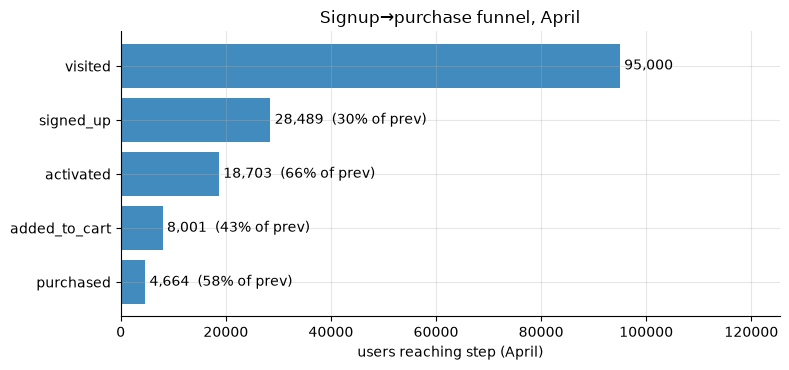

In [5]:
# Overall funnel for the latest month (April): counts, step conversion, cumulative.
april = funnel[funnel["period"] == "April"]
counts = april[STEPS].sum()
funnel_tbl = pd.DataFrame({"users": counts})
funnel_tbl["step_conv"] = counts / counts.shift(1)
funnel_tbl["cum_conv"] = counts / counts.iloc[0]
print(funnel_tbl.round(4))

fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(STEPS))[::-1]
ax.barh(y, counts.values, color="tab:blue", alpha=0.85)
ax.set_yticks(y, STEPS)
for yi, (step, c) in zip(y, counts.items()):
    label = f"{c:,}"
    if step != "visited":
        label += f"  ({funnel_tbl.loc[step, 'step_conv']:.0%} of prev)"
    ax.text(c + 800, yi, label, va="center")
ax.set_xlim(0, counts.iloc[0] * 1.32)
ax.set_xlabel("users reaching step (April)")
ax.set_title("Signup→purchase funnel, April")
plt.show()

### Segment cuts

The pooled funnel hides everything interesting. The two questions worth asking of every
step: *who* converts worst here, and is that a product problem (same audience, different
experience — e.g. platform) or an audience problem (different intent — e.g. channel)?

Step conversion by platform (April):
           visited -> signed_up  signed_up -> activated  activated -> added_to_cart  added_to_cart -> purchased
platform                                                                                                      
android                  0.299                   0.626                       0.292                       0.568
ios                      0.298                   0.693                       0.544                       0.592
web                      0.304                   0.655                       0.465                       0.582 

Step conversion by channel (April):
              visited -> signed_up  signed_up -> activated  activated -> added_to_cart  added_to_cart -> purchased
channel                                                                                                          
organic                     0.371                   0.676                       0.435                       0.603
paid_search               

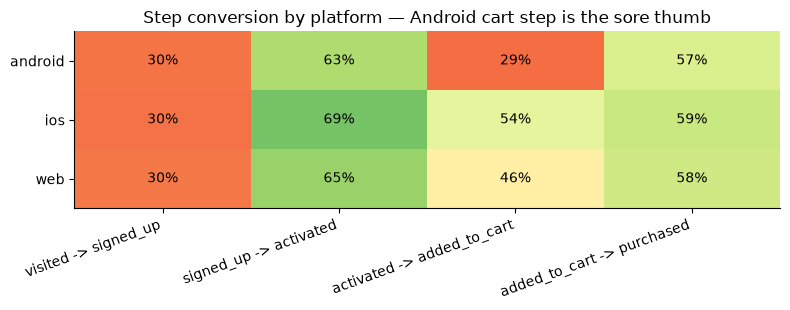

In [6]:
def step_rates(df: pd.DataFrame, by: str) -> pd.DataFrame:
    """Step-to-step conversion rates by segment."""
    g = df.groupby(by)[STEPS].sum()
    out = pd.DataFrame(index=g.index)
    for prev_s, s in zip(STEPS[:-1], STEPS[1:]):
        out[f"{prev_s} -> {s}"] = g[s] / g[prev_s]
    return out


by_platform = step_rates(april, "platform")
by_channel = step_rates(april, "channel")
print("Step conversion by platform (April):\n", by_platform.round(3), "\n")
print("Step conversion by channel (April):\n", by_channel.round(3))

fig, ax = plt.subplots(figsize=(8, 3.2))
im = ax.imshow(by_platform.to_numpy(), cmap="RdYlGn", vmin=0.15, vmax=0.85, aspect="auto")
ax.set_xticks(range(by_platform.shape[1]), by_platform.columns, rotation=20, ha="right")
ax.set_yticks(range(by_platform.shape[0]), by_platform.index)
for i in range(by_platform.shape[0]):
    for j in range(by_platform.shape[1]):
        ax.text(j, i, f"{by_platform.iloc[i, j]:.0%}", ha="center", va="center")
ax.set_title("Step conversion by platform — Android cart step is the sore thumb")
ax.grid(False)
plt.show()

### Finding the binding constraint

"Which step do we fix first?" The junior answer is "the lowest rate". Wrong twice over.
The lowest step rate may (a) be low for every product on earth (visit→signup) or (b) sit
on so little traffic that fixing it barely moves purchases. The senior tool is a
**headroom analysis**: for each step × segment, compute the extra purchases you'd get if
that segment's step rate rose to the best segment's rate at that step, holding the
segment's own downstream rates fixed:

$$\Delta\text{purchases} = N_{\text{prev step, seg}} \times (r_{\text{benchmark}} - r_{\text{seg}}) \times \prod_{\text{later steps}} r_{\text{seg}}$$

Then rank. This turns "rates" into a common currency (purchases) that a roadmap
discussion can actually use.

In [7]:
def headroom(df: pd.DataFrame, seg_col: str) -> pd.DataFrame:
    g = df.groupby(seg_col)[STEPS].sum()
    rows = []
    for i in range(1, len(STEPS)):
        prev_s, s = STEPS[i - 1], STEPS[i]
        rate = g[s] / g[prev_s]
        bench_seg, bench = rate.idxmax(), rate.max()
        for seg in g.index.drop(bench_seg):
            downstream = np.prod(
                [g.loc[seg, STEPS[j]] / g.loc[seg, STEPS[j - 1]]
                 for j in range(i + 1, len(STEPS))]
            )
            rows.append({
                "dimension": seg_col, "segment": seg, "step": f"{prev_s} -> {s}",
                "rate": rate[seg], "benchmark": bench, "benchmark_seg": bench_seg,
                "extra_purchases": g.loc[seg, prev_s] * (bench - rate[seg]) * downstream,
            })
    return pd.DataFrame(rows)


hr = (pd.concat([headroom(april, "platform"), headroom(april, "channel")])
      .sort_values("extra_purchases", ascending=False)
      .reset_index(drop=True))
print(hr.head(8).round(3))
print(f"\nApril purchases actually observed: {april['purchased'].sum():,}")

  dimension      segment                        step   rate  benchmark benchmark_seg  extra_purchases
0  platform      android  activated -> added_to_cart  0.292      0.544           ios         1018.216
1   channel  paid_social        visited -> signed_up  0.191      0.396      referral          795.140
2   channel  paid_search        visited -> signed_up  0.318      0.396      referral          290.226
3  platform          web  activated -> added_to_cart  0.465      0.544           ios          219.566
4   channel  paid_social  added_to_cart -> purchased  0.478      0.615      referral          211.494
5   channel  paid_social      signed_up -> activated  0.579      0.685   paid_search          136.059
6  platform      android      signed_up -> activated  0.626      0.693           ios          125.638
7   channel      organic        visited -> signed_up  0.371      0.396      referral          123.793

April purchases actually observed: 4,664


The analysis recovers the planted defect. Interpreting the ranking like a senior analyst:

- **Android `activated -> added_to_cart` tops the ranking** — its rate is roughly
  half of iOS's, worth on the order of 1,000 incremental purchases/month (versus ~4,700
  total). Same audience intent, same product intent, different UX: the benchmark is
  *credible* and this is the binding constraint. File the bug.
- The big **channel** rows (paid_social signup vs the referral benchmark) rank high on
  raw headroom but the benchmark is **not credible**: referral visitors arrive
  pre-convinced; paid-social visitors are cold. Cross-*channel* gaps mostly measure
  audience intent, not product defects. Cross-*platform* gaps within the same channel mix
  are far closer to like-for-like.
- Headroom analysis is a **prioritization heuristic, not a causal estimate** — it assumes
  the gap is closable and downstream rates hold. Before staffing a quarter against it,
  validate with an experiment
  ([../02_ab_testing/01_ab_test_end_to_end.ipynb](../02_ab_testing/01_ab_test_end_to_end.ipynb)).

## 5. Conversion decomposition: mix shift vs rate change

The classic senior screen, verbatim from real interviews:

> *"Visit→purchase conversion fell from March to April. The PM says the checkout
> redesign failed. Every channel's own conversion actually improved. Reconcile this and
> quantify how much of the change is traffic mix vs real rate movement."*

First, look at the puzzle. Overall conversion is a weighted average
$R = \sum_s w_s r_s$ (weights = traffic share, rates = per-segment conversion), so it
can fall while every $r_s$ rises if weight shifts toward low-$r$ segments — Simpson's
paradox in its business costume
(see [../01_statistical_foundations/04_statistical_traps.ipynb](../01_statistical_foundations/04_statistical_traps.ipynb)).

In [8]:
seg = (funnel.groupby(["period", "channel"], sort=False)
       .agg(visitors=("purchased", "size"), purchases=("purchased", "sum")))
seg["share"] = seg["visitors"] / seg.groupby("period")["visitors"].transform("sum")
seg["conv"] = seg["purchases"] / seg["visitors"]

puzzle = seg.unstack("period").loc[CHANNELS]
puzzle_view = pd.DataFrame({
    "share_Mar": puzzle[("share", "March")], "share_Apr": puzzle[("share", "April")],
    "conv_Mar": puzzle[("conv", "March")], "conv_Apr": puzzle[("conv", "April")],
})
puzzle_view["conv_change_pp"] = (puzzle_view["conv_Apr"] - puzzle_view["conv_Mar"]) * 100
print(puzzle_view.round(4))

overall = funnel.groupby("period", sort=False)["purchased"].mean()
print(f"\nOverall conversion: March {overall['March']:.4f}, April {overall['April']:.4f}, "
      f"change {(overall['April'] - overall['March']) * 100:+.2f}pp")
print("Every channel improved; the overall rate fell. Now decompose it.")

             share_Mar  share_Apr  conv_Mar  conv_Apr  conv_change_pp
channel                                                              
organic         0.3982     0.3015    0.0619    0.0658          0.3833
paid_search     0.2522     0.2192    0.0514    0.0566          0.5244
paid_social     0.1496     0.3486    0.0195    0.0224          0.2977
referral        0.2000     0.1307    0.0648    0.0691          0.4331

Overall conversion: March 0.0535, April 0.0491, change -0.44pp
Every channel improved; the overall rate fell. Now decompose it.


### Implementing the decomposition

With $\Delta w_s = w_s^{(1)} - w_s^{(0)}$ and $\Delta r_s = r_s^{(1)} - r_s^{(0)}$, the
exact identity is

$$\Delta R \;=\; \underbrace{\sum_s \Delta w_s\, r_s^{(0)}}_{\text{mix shift}}
\;+\; \underbrace{\sum_s w_s^{(0)} \Delta r_s}_{\text{rate change}}
\;+\; \underbrace{\sum_s \Delta w_s \Delta r_s}_{\text{interaction}}$$

That is the **Laspeyres** (base-period-weighted) form; evaluating at end-period weights
instead flips which term absorbs the interaction. The symmetric **midpoint** form
(average the weights/rates across periods) kills the interaction term entirely and is
what I recommend writing on the whiteboard:

$$\Delta R \;=\; \sum_s \Delta w_s\, \bar r_s \;+\; \sum_s \bar w_s\, \Delta r_s,
\qquad \bar x = \tfrac{x^{(0)} + x^{(1)}}{2}$$

Either way the parts **must sum exactly to the total** — that's your unit test, and the
first thing an interviewer checks.

In [9]:
def decompose_rate_change(df, seg_col, flag_col, period_col, p0, p1, method="midpoint"):
    """Split R(p1) - R(p0) into per-segment mix and rate contributions (+ interaction)."""
    g = df.groupby([period_col, seg_col]).agg(n=(flag_col, "size"), c=(flag_col, "sum"))
    n0, n1 = g.loc[p0, "n"], g.loc[p1, "n"]
    out = pd.DataFrame({
        "w0": n0 / n0.sum(), "w1": n1 / n1.sum(),
        "r0": g.loc[p0, "c"] / n0, "r1": g.loc[p1, "c"] / n1,
    })
    dw, dr = out["w1"] - out["w0"], out["r1"] - out["r0"]
    if method == "laspeyres":
        out["mix"] = dw * out["r0"]
        out["rate"] = out["w0"] * dr
        out["interaction"] = dw * dr
    elif method == "midpoint":
        out["mix"] = dw * (out["r0"] + out["r1"]) / 2
        out["rate"] = (out["w0"] + out["w1"]) / 2 * dr
    else:
        raise ValueError(method)
    total = (out["w1"] * out["r1"]).sum() - (out["w0"] * out["r0"]).sum()
    parts = out[[c for c in ("mix", "rate", "interaction") if c in out]].sum().sum()
    assert np.isclose(total, parts), "decomposition must sum exactly to the total change"
    return out


lasp = decompose_rate_change(funnel, "channel", "purchased", "period",
                             "March", "April", method="laspeyres")
print("Laspeyres decomposition (contributions in pp):")
print((lasp[["mix", "rate", "interaction"]] * 100).round(3).loc[CHANNELS])
print((lasp[["mix", "rate", "interaction"]] * 100).sum().round(3).rename("TOTAL"))

Laspeyres decomposition (contributions in pp):
               mix   rate  interaction
channel                               
organic     -0.599  0.153       -0.037
paid_search -0.169  0.132       -0.017
paid_social  0.387  0.045        0.059
referral    -0.449  0.087       -0.030
mix           -0.830
rate           0.416
interaction   -0.025
Name: TOTAL, dtype: float64


Midpoint decomposition (contributions in pp):
               mix   rate
channel                  
organic     -0.618  0.134
paid_search -0.178  0.124
paid_social  0.417  0.074
referral    -0.464  0.072
mix    -0.843
rate    0.403
Name: TOTAL, dtype: float64

Headline: overall -0.44pp = mix -0.84pp + rate +0.40pp


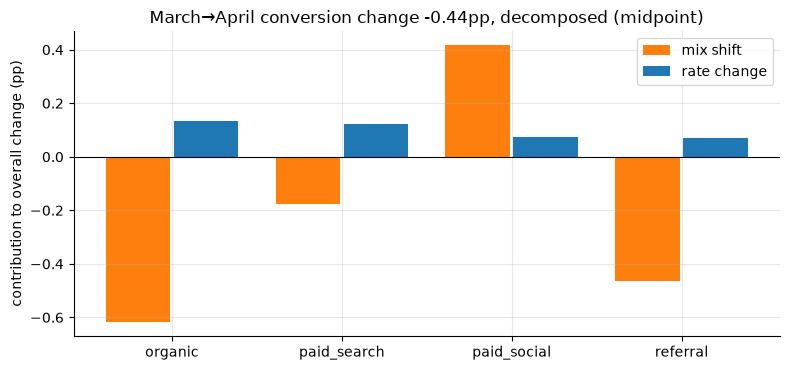

In [10]:
mid = decompose_rate_change(funnel, "channel", "purchased", "period",
                            "March", "April", method="midpoint")
tot_mix, tot_rate = mid["mix"].sum() * 100, mid["rate"].sum() * 100
d_overall = (overall["April"] - overall["March"]) * 100

print("Midpoint decomposition (contributions in pp):")
print((mid[["mix", "rate"]] * 100).round(3).loc[CHANNELS])
print((mid[["mix", "rate"]] * 100).sum().round(3).rename("TOTAL"))
print(f"\nHeadline: overall {d_overall:+.2f}pp = mix {tot_mix:+.2f}pp "
      f"+ rate {tot_rate:+.2f}pp")

fig, ax = plt.subplots(figsize=(8, 3.8))
contrib = (mid[["mix", "rate"]] * 100).loc[CHANNELS]
x = np.arange(len(CHANNELS))
ax.bar(x - 0.2, contrib["mix"], width=0.38, label="mix shift", color="tab:orange")
ax.bar(x + 0.2, contrib["rate"], width=0.38, label="rate change", color="tab:blue")
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(x, CHANNELS)
ax.set_ylabel("contribution to overall change (pp)")
ax.set_title(f"March→April conversion change {d_overall:+.2f}pp, decomposed (midpoint)")
ax.legend()
plt.show()

The decomposition recovers the planted truth: a mix headwind of roughly −0.8pp (the
paid-social campaign tripling the share of the lowest-converting traffic) partially
offset by a genuine rate tailwind of roughly +0.4pp (the checkout redesign working in
every channel). The one-sentence readout for the PM:

> *"Conversion fell ~0.4pp, but that is a −0.8pp traffic-mix effect from scaling paid
> social, masking a +0.4pp real improvement from checkout. The redesign worked; the
> campaign changed who shows up. If the campaign's marginal buyers are LTV-positive,
> both decisions were right — the blended rate was the wrong scoreboard."*

Practical notes that mark seniority:

- **State your weight convention.** Laspeyres/Paasche differ by the interaction term;
  with big simultaneous swings in both mix and rates the interaction can be material —
  report it, don't silently fold it in.
- This generalizes to any weighted-average metric (revenue/user by country, CTR by
  surface) and nests: you can decompose the rate term again by platform within channel.
- Mix shift is not "noise to be excused" — if mix keeps drifting toward low-value
  traffic, that *is* the business story. The decomposition tells you which conversation
  to have (marketing efficiency vs product regression), which is its entire point.

## 6. Cohort retention: matrix and curve families

Funnels measure the first conversion; **retention** measures whether value recurs — and
retention curves, not topline actives, are where product-market fit is visible. Setup:

- Users are grouped by **signup week** (the cohort); for each cohort we track the share
  active $k$ weeks later. We use *bounded (window) retention*: active during week $k$
  exactly. Unbounded/"ever returned after week k" variants are also used; always state
  which one you mean, they differ by several points.
- The matrix is a **triangle**: a cohort born in week 20 can only be observed for a few
  weeks. Averaging across incomplete cohorts is pitfall #2 in §8.

Simulation ground truth (a standard two-type mixture — the probabilistic version of this
becomes the shifted-beta-geometric LTV model in
[./03_ltv_modeling.ipynb](./03_ltv_modeling.ipynb)): each cohort is a blend of
**casuals** (geometric one-way churn, hazard 0.55/week) and **cores** (active any given
week with prob 0.78, indefinitely). The core share grows across cohorts from 18% to
~29.5% — the product is improving — so true plateaus rise cohort over cohort.

In [11]:
N_COHORTS = 24                      # weekly signup cohorts, calendar weeks 0..23
LAST_WEEK = N_COHORTS - 1
cohort_sizes = np.array([700 + 25 * w if w < 20 else 480 for w in range(N_COHORTS)])
core_share = 0.18 + 0.005 * np.arange(N_COHORTS)     # product improving over time
P_CORE_ACTIVE = 0.78                # cores: weekly activity probability (flickers)
P_CASUAL_DIE = 0.55                 # casuals: geometric hazard, then gone for good

cohort_of_user = np.repeat(np.arange(N_COHORTS), cohort_sizes)
n_sim_users = cohort_of_user.size
is_core = rng.random(n_sim_users) < core_share[cohort_of_user]
casual_life = rng.geometric(P_CASUAL_DIE, size=n_sim_users)   # active weeks 0..life-1

# Long format: one row per user per observed calendar week.
weeks_obs = LAST_WEEK - cohort_of_user + 1
user_rep = np.repeat(np.arange(n_sim_users), weeks_obs)
k = np.arange(weeks_obs.sum()) - np.repeat(np.cumsum(weeks_obs) - weeks_obs, weeks_obs)
active = np.where(is_core[user_rep], rng.random(user_rep.size) < P_CORE_ACTIVE,
                  k < casual_life[user_rep])
active[k == 0] = True               # signup week counts as active by definition

activity = pd.DataFrame({
    "user_id": user_rep, "cohort_week": cohort_of_user[user_rep],
    "week": cohort_of_user[user_rep] + k, "k": k, "active": active,
})
print(f"{n_sim_users:,} users, {len(activity):,} user-weeks; "
      f"pause cohorts 20-23 sized {cohort_sizes[-1]} (marketing pause)")

20,670 users, 260,050 user-weeks; pause cohorts 20-23 sized 480 (marketing pause)


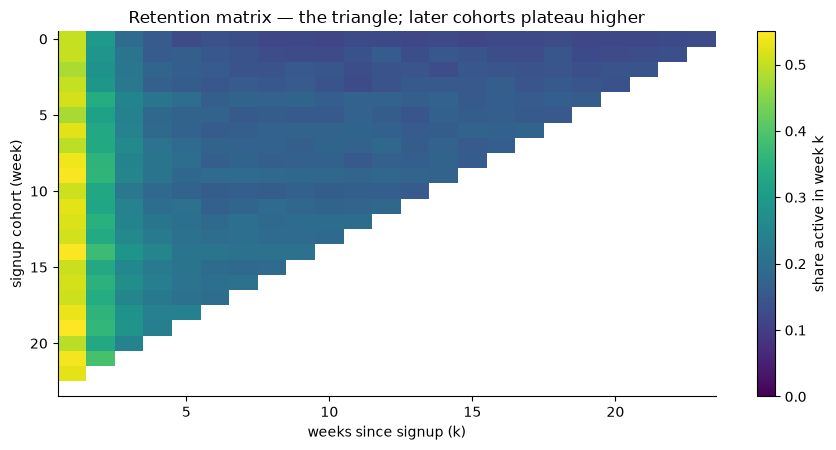

Week-8 retention by cohort (observable cohorts only):
cohort_week
0     0.117
1     0.131
2     0.141
3     0.148
4     0.172
5     0.162
6     0.173
7     0.174
8     0.167
9     0.187
10    0.162
11    0.192
12    0.190
13    0.191
14    0.207
15    0.192


In [12]:
retention = activity.pivot_table(index="cohort_week", columns="k",
                                 values="active", aggfunc="mean")

fig, ax = plt.subplots(figsize=(9, 4.6))
mat = np.ma.masked_invalid(retention.iloc[:, 1:].to_numpy())   # drop k=0 (=1 by def.)
im = ax.imshow(mat, cmap="viridis", vmin=0, vmax=0.55, aspect="auto",
               extent=[0.5, LAST_WEEK + 0.5, N_COHORTS - 0.5, -0.5])
ax.set_xlabel("weeks since signup (k)")
ax.set_ylabel("signup cohort (week)")
ax.set_title("Retention matrix — the triangle; later cohorts plateau higher")
fig.colorbar(im, ax=ax, label="share active in week k")
ax.grid(False)
plt.show()

wk8 = retention[8].dropna()
print("Week-8 retention by cohort (observable cohorts only):")
print(wk8.round(3).to_string())

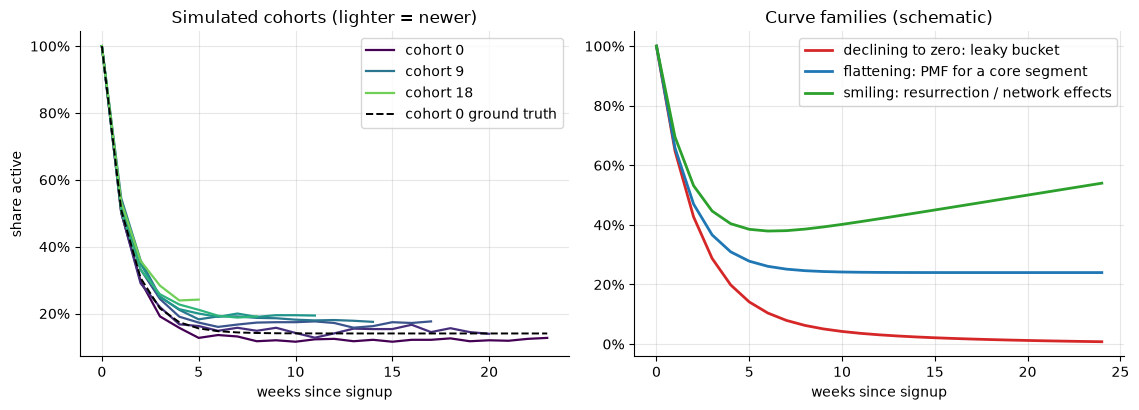

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))

# Left: our simulated cohorts + ground-truth overlay for the oldest cohort.
cmap = plt.get_cmap("viridis")
for w in range(0, 20, 3):
    curve = retention.loc[w].dropna()
    axes[0].plot(curve.index, curve.values, color=cmap(w / 23), lw=1.6,
                 label=f"cohort {w}" if w in (0, 9, 18) else None)
kk = np.arange(0, LAST_WEEK + 1)
truth0 = core_share[0] * P_CORE_ACTIVE + (1 - core_share[0]) * (1 - P_CASUAL_DIE) ** kk
truth0[0] = 1.0
axes[0].plot(kk, truth0, "k--", lw=1.4, label="cohort 0 ground truth")
axes[0].set_xlabel("weeks since signup")
axes[0].set_ylabel("share active")
axes[0].yaxis.set_major_formatter(pct0)
axes[0].set_title("Simulated cohorts (lighter = newer)")
axes[0].legend()

# Right: the three canonical curve families (schematic).
ks = np.arange(0, 25)
axes[1].plot(ks, 0.9 * 0.62 ** ks + 0.1 * 0.9 ** ks, lw=2, color="tab:red",
             label="declining to zero: leaky bucket")
axes[1].plot(ks, 0.24 + 0.76 * 0.55 ** ks, lw=2, color="tab:blue",
             label="flattening: PMF for a core segment")
axes[1].plot(ks, np.minimum(0.30 + 0.70 * 0.55 ** ks + 0.010 * ks, 1), lw=2,
             color="tab:green", label="smiling: resurrection / network effects")
axes[1].set_xlabel("weeks since signup")
axes[1].yaxis.set_major_formatter(pct0)
axes[1].set_title("Curve families (schematic)")
axes[1].legend()
plt.show()

How to read retention curves in an interview (or a board deck):

- **Declining to zero** — no habitual segment; growth is a treadmill and paid
  acquisition is renting revenue. LTV is bounded by the area under a vanishing curve.
- **Flattening to a plateau** — a core segment has formed a habit; the plateau height ×
  cohort size is your durable user base, and it's the quantity that compounds. This is
  the empirical signature people mean by product-market fit.
- **Smiling** — retention *rising* at high $k$: resurrection (win-back, seasonality) or
  network effects kicking in. Rare and valuable; verify it isn't a definition artifact
  (e.g. notification-triggered "activity").
- **The comparison that matters is cohort-over-cohort at fixed $k$** (read the matrix
  down a column, e.g. the week-8 column above rising from ~0.12 toward ~0.20): later
  cohorts flattening higher is the cleanest evidence the product is improving —
  independent of growth spend, which topline WAU/DAU hopelessly confounds.

Survival-analysis machinery for the same question (censoring, hazards, covariates) is in
[./02_churn_survival.ipynb](./02_churn_survival.ipynb); the SQL retention query pattern
is in [../07_sql_and_big_data/02_sql_product_analytics.ipynb](../07_sql_and_big_data/02_sql_product_analytics.ipynb).

## 7. Growth accounting: new / retained / resurrected / churned

Topline WAU can grow while the product bleeds — growth accounting is the decomposition
that catches it. For each week $t$, partition active users by what they did in week
$t{-}1$:

- **new**: first week ever (here, their signup week);
- **retained**: active in $t$ and in $t{-}1$;
- **resurrected**: active in $t$, inactive in $t{-}1$, signed up earlier;
- **churned**: active in $t{-}1$, inactive in $t$ (counted against week $t$).

Two identities must hold *exactly* (they're definitions, not models — assert them):

$$\text{WAU}_t = \text{new}_t + \text{retained}_t + \text{resurrected}_t, \qquad
\Delta \text{WAU}_t = \text{new}_t + \text{resurrected}_t - \text{churned}_t$$

The **quick ratio** $(\text{new}+\text{resurrected})/\text{churned}$ summarizes the
balance: above 1 you grow, near 1 you tread water. We compute statuses with a
self-merge on (user, week−1) — the same join you'd write in SQL.

In [14]:
active_uw = activity.loc[activity["active"], ["user_id", "week"]]
prev_uw = active_uw.assign(week=active_uw["week"] + 1)        # "was active in week-1"

m = active_uw.merge(prev_uw, on=["user_id", "week"], how="outer", indicator=True)
m = m[m["week"] <= LAST_WEEK].copy()
m["cohort_week"] = m["user_id"].map(pd.Series(cohort_of_user))
now = m["_merge"].isin(["left_only", "both"])       # active in week t
was = m["_merge"].isin(["right_only", "both"])      # active in week t-1
m["status"] = np.select(
    [now & (m["week"] == m["cohort_week"]), now & was, now & ~was, ~now & was],
    ["new", "retained", "resurrected", "churned"], default="?")
assert (m["status"] != "?").all()

ga = (m.pivot_table(index="week", columns="status", aggfunc="size", fill_value=0)
      [["new", "retained", "resurrected", "churned"]])
ga["wau"] = ga["new"] + ga["retained"] + ga["resurrected"]

# Identity checks against independently computed WAU.
wau_direct = active_uw.groupby("week").size()
assert ga["wau"].equals(wau_direct)
dwau = ga["wau"].diff()
assert np.allclose(dwau.iloc[1:],
                   (ga["new"] + ga["resurrected"] - ga["churned"]).iloc[1:])
print("identities hold: WAU = new+retained+resurrected;  dWAU = new+res-churned\n")

ga["quick_ratio"] = np.where(ga["churned"] > 0,
                             (ga["new"] + ga["resurrected"]) / ga["churned"], np.nan)
print(ga.iloc[[1, 5, 10, 15, 19, 20, 21, 22, 23]].round(2))

identities hold: WAU = new+retained+resurrected;  dWAU = new+res-churned

status   new  retained  resurrected  churned   wau  quick_ratio
week                                                           
1        725       351            0      349  1076         2.08
5        825       923           79      741  1827         1.22
10       950      1634          261      985  2845         1.23
15      1075      2364          474     1239  3913         1.25
19      1175      3155          644     1516  4974         1.20
20       480      3374          659     1600  4513         0.71
21       480      3152          741     1361  4373         0.90
22       480      3101          789     1272  4370         1.00
23       480      3177          782     1193  4439         1.06


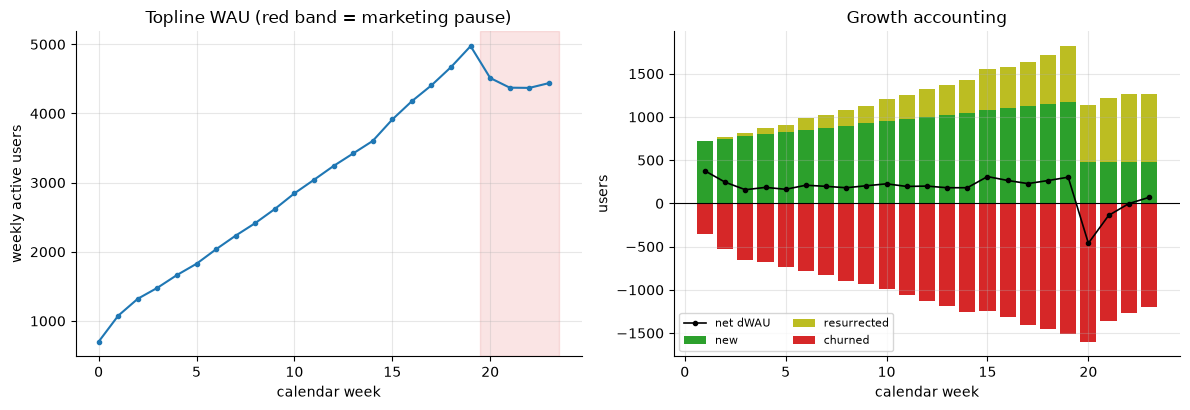

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

axes[0].plot(ga.index, ga["wau"], marker="o", ms=3, color="tab:blue")
axes[0].axvspan(19.5, 23.5, color="tab:red", alpha=0.12)
axes[0].set_xlabel("calendar week")
axes[0].set_ylabel("weekly active users")
axes[0].set_title("Topline WAU (red band = marketing pause)")

w = ga.index[1:]
axes[1].bar(w, ga.loc[w, "new"], color="tab:green", label="new")
axes[1].bar(w, ga.loc[w, "resurrected"], bottom=ga.loc[w, "new"],
            color="tab:olive", label="resurrected")
axes[1].bar(w, -ga.loc[w, "churned"], color="tab:red", label="churned")
axes[1].plot(w, dwau.loc[w], color="k", marker="o", ms=3, lw=1.2, label="net dWAU")
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_xlabel("calendar week")
axes[1].set_ylabel("users")
axes[1].set_title("Growth accounting")
axes[1].legend(loc="lower left", ncols=2, fontsize=8)
plt.show()

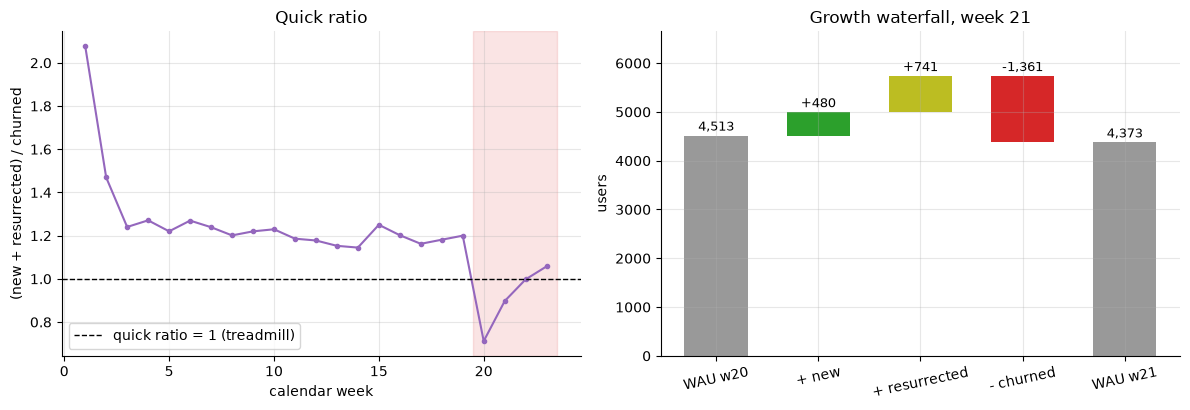

week 21: 4,513 + 480 new + 741 resurrected - 1,361 churned = 4,373


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

qr = ga["quick_ratio"].iloc[1:]
axes[0].plot(qr.index, qr.values, marker="o", ms=3, color="tab:purple")
axes[0].axhline(1.0, color="k", ls="--", lw=1, label="quick ratio = 1 (treadmill)")
axes[0].axvspan(19.5, 23.5, color="tab:red", alpha=0.12)
axes[0].set_xlabel("calendar week")
axes[0].set_ylabel("(new + resurrected) / churned")
axes[0].set_title("Quick ratio")
axes[0].legend()

# Growth waterfall for week 21 (inside the pause).
t = 21
start, end = int(ga.loc[t - 1, "wau"]), int(ga.loc[t, "wau"])
new_t, res_t, chn_t = (int(v) for v in ga.loc[t, ["new", "resurrected", "churned"]])
assert end == start + new_t + res_t - chn_t
labels = [f"WAU w{t-1}", "+ new", "+ resurrected", "- churned", f"WAU w{t}"]
vals = [start, new_t, res_t, -chn_t, end]
bottoms = [0, start, start + new_t, start + new_t + res_t, 0]
colors = ["0.6", "tab:green", "tab:olive", "tab:red", "0.6"]
peak = start + new_t + res_t
for i, (v, b, c) in enumerate(zip(vals, bottoms, colors)):
    axes[1].bar(i, v, bottom=b, color=c, width=0.62)
    axes[1].text(i, max(b, b + v) + peak * 0.018,
                 f"{v:+,.0f}" if 0 < i < 4 else f"{v:,.0f}", ha="center", fontsize=9)
axes[1].set_xticks(range(5), labels, rotation=12)
axes[1].set_ylim(0, peak * 1.16)
axes[1].set_title(f"Growth waterfall, week {t}")
axes[1].set_ylabel("users")
plt.show()

print(f"week {t}: {start:,} + {new_t:,} new + {res_t:,} resurrected "
      f"- {chn_t:,} churned = {end:,}")

The story the charts tell: during the growth phase the quick ratio sits around 1.2 —
healthy but hardly explosive, because churn (mostly fast-decaying casuals) eats most of
each week's new supply. The moment marketing pauses (weeks 20–23), new drops ~60%, the
quick ratio falls to ~0.7 and WAU immediately sheds several hundred users. Note what
happens next: by week 22–23 the quick ratio climbs back toward 1 — *not* because health
returned, but because churn is dominated by recent cohorts, so a smaller intake soon
means a smaller churn pool. WAU stabilizes at a lower plateau held up by the accumulated
core base. Nothing about the *product* changed — retention was improving cohort over
cohort the whole time — the topline was simply propped up by acquisition. That is
precisely the diagnosis growth accounting exists to make, and why "WAU is up" (or down)
is never, by itself, evidence about product health. Caveats worth volunteering: statuses
depend on the activity **window** (weekly churn includes harmless flicker; see exercise
2), and the quick ratio hides composition (new-driven vs resurrection-driven growth age
very differently).

## 8. Pitfalls

### Pitfall 1 — averaging rates without weights

A dashboard shows "average daily conversion" as the mean of daily rates. Days are not
equal-sized: weekends here have low traffic but high conversion. The unweighted mean of
daily rates and the pooled rate answer different questions, and the gap is not small.
(Inference on ratio metrics has the same trap at the user level — delta method in
[../02_ab_testing/05_ratio_metrics_delta_method.ipynb](../02_ab_testing/05_ratio_metrics_delta_method.ipynb).)

In [17]:
days = np.arange(28)
is_weekend = (days % 7) >= 5
visits = np.where(is_weekend, 800, 3000)
conversions = rng.binomial(visits, np.where(is_weekend, 0.09, 0.05))
daily_rate = conversions / visits

unweighted = daily_rate.mean()
pooled = conversions.sum() / visits.sum()
print(f"unweighted mean of daily rates: {unweighted:.4f}   <- 'average day'")
print(f"pooled conversions/visits:      {pooled:.4f}   <- 'average visit'")
print(f"gap: {(unweighted - pooled) * 100:+.2f}pp from weighting alone")

unweighted mean of daily rates: 0.0601   <- 'average day'
pooled conversions/visits:      0.0528   <- 'average visit'
gap: +0.74pp from weighting alone


Neither number is *wrong* — one weights days equally, the other weights visits equally —
but they differ by ~0.7pp here and a dashboard that silently switches between them will
manufacture "trends". Always know (and state) the denominator of any rate you report.

### Pitfall 2 — blending incomplete cohorts (retention triangle abuse)

"Company week-12 retention" computed by averaging the retention matrix down each column
has a survivorship-of-cohorts problem: only *old* cohorts have reached week 12. When
retention improves over time (as it does in our simulation, by construction), the
blended curve's tail reflects only the old, worse cohorts — it understates the product
you're shipping today. The same artifact creates fake "kinks" wherever cohort quality or
size changed.

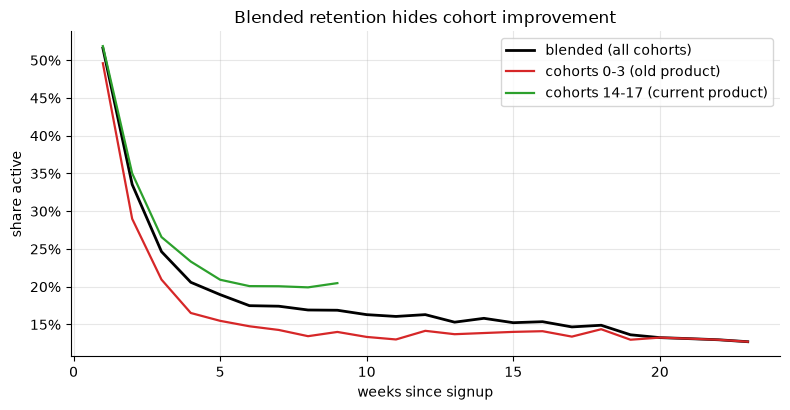

week-6 retention:  blended 0.175  vs current-product cohorts 0.201
blended week-12+ tail draws ONLY on cohorts 0-11 (core share 18%-24% vs 30% today)


In [18]:
blended = retention.mean(axis=0)                      # column mean over available cohorts
early = retention.loc[0:3].mean(axis=0)               # oldest 4 cohorts
recent = retention.loc[14:17].mean(axis=0).dropna()   # newer cohorts, short observation

fig, ax = plt.subplots()
ax.plot(blended.index[1:], blended.values[1:], "k-", lw=2, label="blended (all cohorts)")
ax.plot(early.index[1:], early.values[1:], color="tab:red", lw=1.6,
        label="cohorts 0-3 (old product)")
ax.plot(recent.index[1:], recent.values[1:], color="tab:green", lw=1.6,
        label="cohorts 14-17 (current product)")
ax.set_xlabel("weeks since signup")
ax.set_ylabel("share active")
ax.yaxis.set_major_formatter(pct0)
ax.set_title("Blended retention hides cohort improvement")
ax.legend()
plt.show()

k_cmp = 6
print(f"week-{k_cmp} retention:  blended {blended[k_cmp]:.3f}  "
      f"vs current-product cohorts {recent[k_cmp]:.3f}")
print(f"blended week-12+ tail draws ONLY on cohorts 0-{N_COHORTS - 1 - 12} "
      f"(core share {core_share[0]:.0%}-{core_share[N_COHORTS - 1 - 12]:.0%} "
      f"vs {core_share[-1]:.0%} today)")

Fixes: plot cohort curves separately (or small multiples of cohort groups); when you
must summarize, fix $k$ and compare cohorts at the same age; never let a mean run over
a triangle's ragged edge without saying so.

### Pitfall 3 — units, definitions, and quiet redefinitions

- **Percent vs percentage points.** Conversion moving 5.0% → 4.6% is a drop of 0.4pp
  but 8% relative. In §5 our mix effect (−0.8pp) is ~15% of baseline conversion —
  saying "conversion fell 0.8%" would understate it by an order of magnitude. Senior
  habit: always say "pp" or "relative", never a bare "%".
- **Metric definition drift.** Changing "active" from "opened app" to "opened app or
  received push-triggered sync" resurrects thousands of users overnight; retention
  "improves" with zero product change. Version metric definitions like code, and
  annotate dashboards with definition-change dates (KPI changepoints that coincide with
  releases are the first thing to rule out — see
  [../05_time_series/04_anomaly_detection.ipynb](../05_time_series/04_anomaly_detection.ipynb)).
- **Goodhart at the team level** (§3): any input metric under goal pressure needs its
  counter-metric reported *on the same page*, or it will be gamed — usually without
  anyone intending to cheat.

## 9. Interview corner

**1. "Define a success metric for feature X" (e.g. saved searches on our marketplace).**
Strong answer is a structure, not a metric: (i) state the user-value hypothesis (saved
searches help infrequent buyers return to relevant supply); (ii) define adoption
(% of weekly searchers who save ≥1 search), engagement depth (return visits via
saved-search notification), and the value link (incremental purchases, measured by
experiment, not by correlating adopters vs non-adopters — self-selection); (iii) attach
counter-metrics (notification opt-outs, unsubscribes) so the feature can't "win" by
spamming; (iv) say where it hangs on the north-star tree (demand → frequency). Bonus:
name the evaluation design — holdback experiment, because adopters are self-selected.

**2. "DAU dropped 8% week-over-week — how do you investigate?"** Order matters:
(i) *Data first*: logging/SDK releases, definition changes, bot filters, pipeline
lateness — most 8% drops are instrumentation. (ii) *Calendar*: seasonality, holidays,
DST, comparison-window artifacts (compare YoY and day-of-week aligned). (iii)
*Segment decomposition* (§5 machinery): platform × app-version × country × channel;
quantify each cut's contribution to the −8% (mix vs rate), look for a single segment
explaining most of it (e.g. one app release). (iv) *Growth accounting* (§7): is it new
(acquisition/marketing), retained (product regression), or resurrected (a win-back
campaign ended)? Each implies a different owner. (v) Only then product hypotheses and
external events, with an experiment or event-study if a causal claim is needed
([../03_causal_inference/03_did_synthetic_control.ipynb](../03_causal_inference/03_did_synthetic_control.ipynb)).

**3. "What makes a metric good vs bad?"** Hit the four criteria (sensitive, robust,
directional, hard to game) *with the tension between them*: sessions/user is maximally
sensitive and nearly meaningless as a target; revenue is maximally meaningful and too
noisy to run experiments on (quantify via CV → sample size, §2). A good metric system
resolves the tension by pairing: sensitive input metrics for iteration speed, a robust
north star for direction, counter-metrics for integrity.

**4. "Your north star grew but revenue didn't. Explain."** Enumerate mechanisms, then
say how to distinguish them: (i) lag — north star leads, revenue follows (check
historical lead-lag relationship); (ii) mix — growth came from low-monetization
segments/geos (decompose revenue = north star × $-per-unit, then §5 mix/rate split on
the $-per-unit term); (iii) Goodhart — the north star inflated via definition drift or
gaming (audit the metric's composition); (iv) the tree's causal edge broke — e.g.
purchases grew via discount-subsidized orders with negative margin (check
guardrails/unit economics). The senior move is naming that a north star is a *validated
proxy*, and the validation (edge from north star to revenue) must be re-tested
periodically, ideally with experiments.

**5. "Our quick ratio is 1.2 — is that good?"** Depends on window and stage: quick
ratios shrink toward 1 as the window widens (weekly flicker inflates both churn and
resurrection — exercise 2), so 1.2 weekly and 1.2 monthly are different businesses.
Composition matters: 1.2 driven by resurrection with weak new-user flow ages badly.
And it says nothing about *who*: pair with cohort curves (§6) before calling health.

**6. "The lowest-converting funnel step is visit→signup at ~30%. Should we fix it
first?"** No — lowest rate ≠ binding constraint. Run the headroom analysis (§4):
expected extra purchases from lifting each step×segment to a credible benchmark,
holding downstream fixed. Discuss benchmark credibility (platform gaps are product
bugs; channel gaps are audience intent) and confirm the winner with an experiment.

## 10. Key takeaways

- Design metric **systems**: a north star that proxies value, input metrics teams can
  move, guardrails they must not break, counter-metrics that catch gaming. Every edge in
  the tree is a causal claim worth testing.
- Sensitivity is quantitative: CV → experiment sample size. Revenue-style metrics cost
  ~4x the sample of conversion here; capping helps but changes the estimand.
- A metric can be sensitive, robust, *and* worthless as a target (sessions/user).
  Goodhart is a design constraint, not trivia — fix with value-closer definitions plus
  counter-metrics.
- Funnel priority = **headroom in purchase currency** (traffic × closable gap ×
  downstream conversion), not "lowest rate". Judge benchmark credibility before
  believing a gap is closable.
- Period-over-period change in any weighted-average metric decomposes **exactly** into
  mix + rate (+ interaction). Midpoint weights kill the interaction; the parts must sum
  to the total — assert it.
- Overall conversion can fall while every segment improves (Simpson). Decomposition
  turns that from a paradox into a sentence for the PM.
- Retention curve shape > retention level: flattening curves are the empirical signature
  of product-market fit; compare cohorts at fixed $k$, never blend a ragged triangle.
- Growth accounting identities (WAU = new + retained + resurrected; ΔWAU = new +
  resurrected − churned) split topline motion into acquisition vs product vs win-back.
  Quick ratio < 1 means the treadmill is winning.
- State denominators and windows: unweighted vs pooled rates, weekly vs monthly churn,
  pp vs %. Most "insights" that die in review die on one of these.

## 11. Exercises

**Exercise 1 — step-level decomposition.** Overall visit→purchase conversion is the
*product* of the four step rates, so its change factors multiplicatively:
$\Delta \log R = \sum_k \Delta \log r_k$. Compute each step's log-contribution to the
March→April change using pooled step rates. Which step "deteriorated" most — and why is
that conclusion misleading given §5? (Hint: pooled step rates absorb the mix shift.)

**Exercise 2 — growth accounting windows.** Rebuild the §7 growth accounting on 4-week
periods (`period = week // 4`; active = active in any week of the period). Compare
average quick ratios (use periods/weeks fully inside the growth phase, before week 20).
Explain the direction of the difference.

**Exercise 3 — retention plateau by curve fitting.** Fit
$r(k) = c + A\,b^{k}$ (for $k \ge 1$) to the average retention curve of cohorts 0–2
with `scipy.optimize.curve_fit`. Compare the fitted plateau $c$ with the simulation's
ground truth for those cohorts, $\bar q \times 0.78$. Why is extrapolating a plateau
from 8 weeks of data dangerous in real life?

In [19]:
# --- Solution 1: multiplicative (log) step decomposition ---
g = funnel.groupby("period", sort=False)[STEPS].sum().loc[["March", "April"]]
step_r = pd.DataFrame({
    f"{a} -> {b}": g[b] / g[a] for a, b in zip(STEPS[:-1], STEPS[1:])
})
dlog = np.log(step_r.loc["April"]) - np.log(step_r.loc["March"])
sol1 = pd.DataFrame({"March": step_r.loc["March"], "April": step_r.loc["April"],
                     "dlog": dlog, "share_of_change": dlog / dlog.sum()})
print(sol1.round(4))
total_check = np.log(overall["April"] / overall["March"])
assert np.isclose(dlog.sum(), total_check)
print(f"\nsum of step dlogs = {dlog.sum():+.4f} = dlog(overall conv) -- identity holds")
print("\nThe signup step 'fell' the most — but §5 showed every channel's signup rate "
      "held or rose;\nthe pooled signup rate dropped because traffic shifted toward "
      "paid_social (low signup intent).\nPooled step rates confound mix with rate: "
      "decompose within segments (§5) before blaming a step.")

                             March   April    dlog  share_of_change
visited -> signed_up        0.3352  0.2999 -0.1115           1.3003
signed_up -> activated      0.6674  0.6565 -0.0165           0.1928
activated -> added_to_cart  0.4247  0.4278  0.0072          -0.0841
added_to_cart -> purchased  0.5628  0.5829  0.0351          -0.4090



sum of step dlogs = -0.0857 = dlog(overall conv) -- identity holds

The signup step 'fell' the most — but §5 showed every channel's signup rate held or rose;
the pooled signup rate dropped because traffic shifted toward paid_social (low signup intent).
Pooled step rates confound mix with rate: decompose within segments (§5) before blaming a step.


In [20]:
# --- Solution 2: growth accounting with 4-week windows ---
act_p = (activity.loc[activity["active"], ["user_id", "week"]]
         .assign(period=lambda d: d["week"] // 4)
         .drop_duplicates(["user_id", "period"])[["user_id", "period"]])
prev_p = act_p.assign(period=act_p["period"] + 1)
LAST_PERIOD = LAST_WEEK // 4

mp = act_p.merge(prev_p, on=["user_id", "period"], how="outer", indicator=True)
mp = mp[mp["period"] <= LAST_PERIOD].copy()
mp["cohort_period"] = mp["user_id"].map(pd.Series(cohort_of_user)) // 4
now_p = mp["_merge"].isin(["left_only", "both"])
was_p = mp["_merge"].isin(["right_only", "both"])
mp["status"] = np.select(
    [now_p & (mp["period"] == mp["cohort_period"]), now_p & was_p,
     now_p & ~was_p, ~now_p & was_p],
    ["new", "retained", "resurrected", "churned"], default="?")
gap = (mp.pivot_table(index="period", columns="status", aggfunc="size", fill_value=0)
       [["new", "retained", "resurrected", "churned"]])
gap["quick_ratio"] = (gap["new"] + gap["resurrected"]) / gap["churned"]
print(gap.round(2))

qr_weekly = ga.loc[2:19, "quick_ratio"].mean()      # growth phase, weekly
qr_4week = gap.loc[1:4, "quick_ratio"].mean()       # growth phase, 4-weekly
print(f"\nmean quick ratio, growth phase:  weekly {qr_weekly:.2f}   4-weekly {qr_4week:.2f}")
print("Longer windows absorb the flicker of core users (inactive one week, back the "
      "next),\nso both churned and resurrected shrink and the quick ratio moves. Same "
      "product, different\nnumber — never compare quick ratios across different "
      "activity windows.")

status   new  retained  resurrected  churned  quick_ratio
period                                                   
0       2950         0            0        0          inf
1       3350       969            0     1981         1.69
2       3750      1783            1     2536         1.48
3       4150      2680            2     2854         1.45
4       4550      3721            7     3111         1.46
5       1920      4983            8     3295         0.59

mean quick ratio, growth phase:  weekly 1.22   4-weekly 1.52
Longer windows absorb the flicker of core users (inactive one week, back the next),
so both churned and resurrected shrink and the quick ratio moves. Same product, different
number — never compare quick ratios across different activity windows.


fitted:  c=0.133, A=0.807, b=0.445
truth :  c=0.144 (core share 0.185 x P(active)=0.78), A=0.815, b=0.45


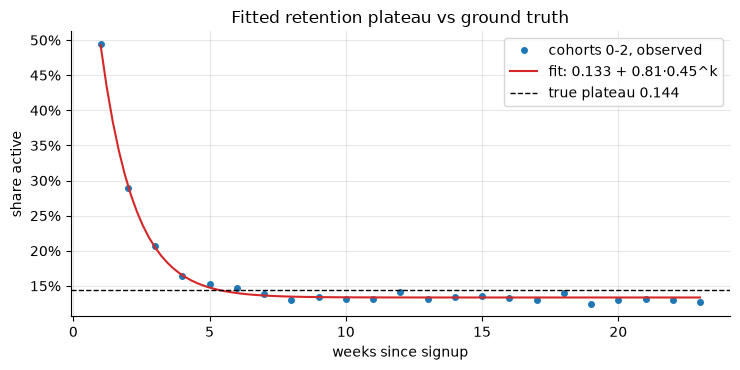

The fit lands within ~1pp of the true plateau because the model matches the generating
process. In real data the 'plateau' keeps decaying slowly (heterogeneous hazards), so
short-window fits overstate long-run retention — the honest tool is a probabilistic model
like sBG (see ./03_ltv_modeling.ipynb) plus waiting for more data.


In [21]:
# --- Solution 3: retention plateau via curve_fit ---
curve = retention.loc[0:2].mean(axis=0).dropna()
kk_fit = curve.index[1:21].to_numpy(float)          # k = 1..20, skip k=0 (=1 by def.)
rr_fit = curve.values[1:21]


def ret_model(k, c, A, b):
    return c + A * b ** k


(c_hat, A_hat, b_hat), _ = curve_fit(ret_model, kk_fit, rr_fit,
                                     p0=[0.15, 0.6, 0.5], bounds=(0, 1))
q_bar = core_share[0:3].mean()
c_true = q_bar * P_CORE_ACTIVE
print(f"fitted:  c={c_hat:.3f}, A={A_hat:.3f}, b={b_hat:.3f}")
print(f"truth :  c={c_true:.3f} (core share {q_bar:.3f} x P(active)={P_CORE_ACTIVE}), "
      f"A={1 - q_bar:.3f}, b={1 - P_CASUAL_DIE:.2f}")

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(curve.index[1:], curve.values[1:], "o", ms=4, label="cohorts 0-2, observed")
ks_line = np.linspace(1, 23, 100)
ax.plot(ks_line, ret_model(ks_line, c_hat, A_hat, b_hat), "-", color="tab:red",
        label=f"fit: {c_hat:.3f} + {A_hat:.2f}·{b_hat:.2f}^k")
ax.axhline(c_true, color="k", ls="--", lw=1, label=f"true plateau {c_true:.3f}")
ax.set_xlabel("weeks since signup")
ax.set_ylabel("share active")
ax.yaxis.set_major_formatter(pct0)
ax.set_title("Fitted retention plateau vs ground truth")
ax.legend()
plt.show()

print("The fit lands within ~1pp of the true plateau because the model matches the "
      "generating\nprocess. In real data the 'plateau' keeps decaying slowly "
      "(heterogeneous hazards), so\nshort-window fits overstate long-run retention — "
      "the honest tool is a probabilistic model\nlike sBG (see ./03_ltv_modeling.ipynb) "
      "plus waiting for more data.")